In [17]:
import asdf
from output_particle import *
import numpy
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
af = asdf.open("exampledata/subsample8.0000.asdf")

In [3]:
af['header']

{'AllDoneTimesteps': 0,
 'AllowDirectIO': 0,
 'AllowGroupFinding': 0,
 'BackupDirectory': '/flare/Abacus/eisenste/Cone_15_new',
 'BackupStepInterval': -1,
 'BoxSize': 2048.0,
 'BoxSizeHMpc': 2048.0,
 'BoxSizeMpc': 3021.9861295558508,
 'BuildDirectory': '/home/eisenste/abacus/build/',
 'CPD': 135,
 'CodeVersion': 'a1adf525-dirty',
 'CompiledWithTracers': 1,
 'Conv_IOMode': 'overwrite',
 'ConvolutionCacheSizeMB': 41.0,
 'ConvolutionL1CacheSizeMB': 1.921875,
 'CoordinateDistanceHMpc': 292.76257419929584,
 'DeltaEtaDrift': 0.009656613253125279,
 'DeltaRedshift': 0.009197211077437,
 'DeltaScaleFactor': 0.007537975119291,
 'DeltaTime': 0.007914458039201,
 'DensityKernelRad2': 0.1600016,
 'DensityKernelRad': 0.4,
 'DerivativeExpansionRadius': 8,
 'DerivativesDirectory': '/flare/Abacus/Derivatives',
 'DidGroupFindingOutput': 0,
 'DirectBPD': 6,
 'DirectsPerParticle': 6845.615180820227,
 'DoGroupFindingOutput': 0,
 'DoGroupFindingTracers': 1,
 'DoSubsampleOutput': 4,
 'DoTimeSliceOutput': 0,
 '

In [4]:
dat = af['data']['timeslice_subsample']

In [9]:
particles = unpack_output_particles_recarray(dat)

In [11]:
particles['pos']

array([[-761.3906  ,    3.34375 ,    9.59375 ],
       [-761.8906  ,   11.9375  ,    8.5     ],
       [-752.75    ,    3.640625,    8.140625],
       ...,
       [ 240.40625 ,   -6.984375,   -6.46875 ],
       [ 247.75    ,   -6.625   ,   -6.203125],
       [ 248.39062 ,   -5.9375  ,  -15.578125]],
      shape=(8324765, 3), dtype=float32)

In [35]:
pos = pd.DataFrame(particles['pos'], columns = ['x','y','z'])

In [20]:
poszslice = pos[(pos['z'] > -10)&(pos['z'] < 10)]
len(poszslice)

88287

Text(0.5, 1.0, 'Redshift 0.1, Subsample \n 20 Mpc/h deep in Z direction')

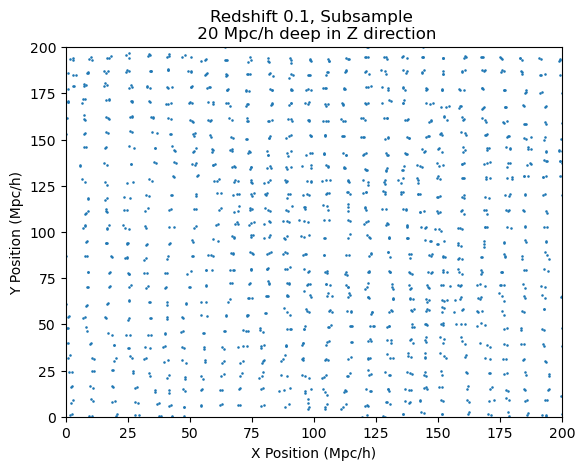

In [47]:
plt.scatter(poszslice['x'],poszslice['y'],s=0.7)
plt.xlim(0,200)
plt.ylim(0,200)
plt.xlabel("X Position (Mpc/h)")
plt.ylabel("Y Position (Mpc/h)")
plt.title("Redshift 0.1, Subsample \n 20 Mpc/h deep in Z direction")

In [34]:
vel = pd.DataFrame(particles['vel'], columns = ['vx','vy','vz'])

Text(0.5, 0, 'Z Velocity (km/s)')

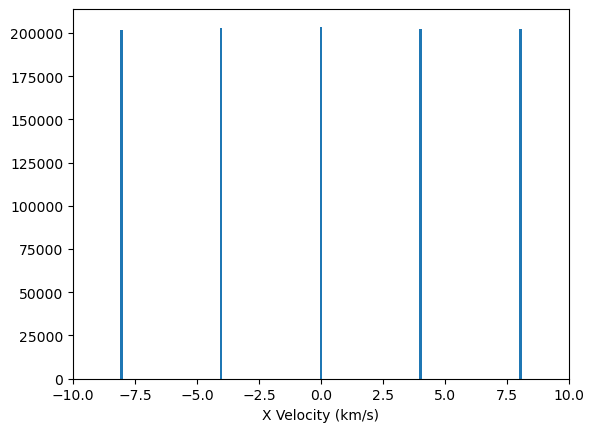

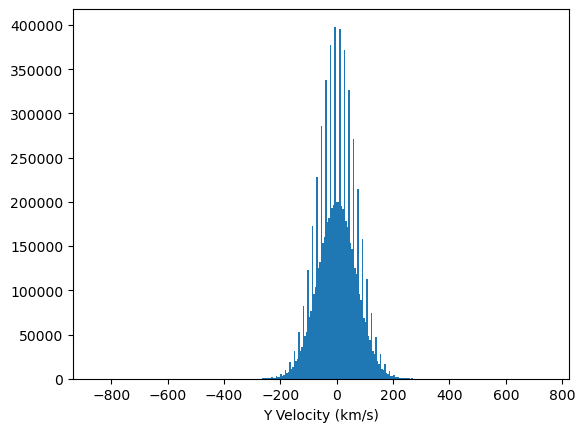

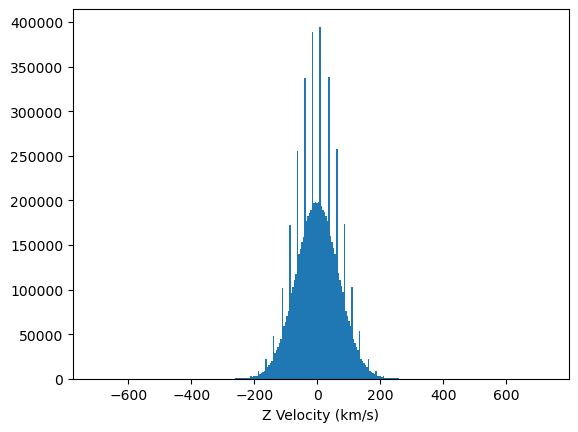

In [42]:
plt.figure()
plt.hist(vel['vx'],bins=np.linspace(-10,10,num=210))
plt.xlabel('X Velocity (km/s)')
plt.xlim(-10,10)

plt.figure()
plt.hist(vel['vy'],bins=300)
plt.xlabel('Y Velocity (km/s)')

plt.figure()
plt.hist(vel['vz'],bins=300)
plt.xlabel('Z Velocity (km/s)')

In [44]:
pid = pd.DataFrame(particles['pid'], columns = ['x','y','z'])

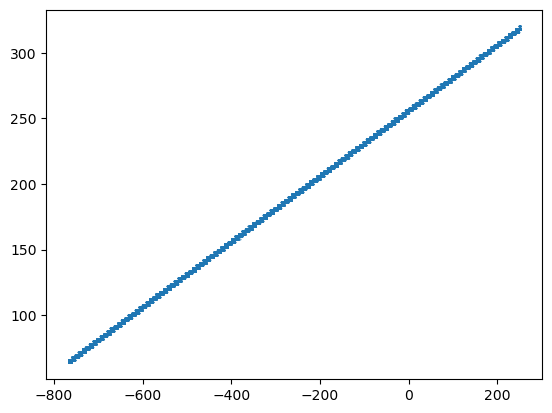

In [46]:
plt.scatter(pos['x'],pid['x'],s=0.1)
#pid: ordered triple, corresponds to original position

(array([      0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0., 8324765.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0., 

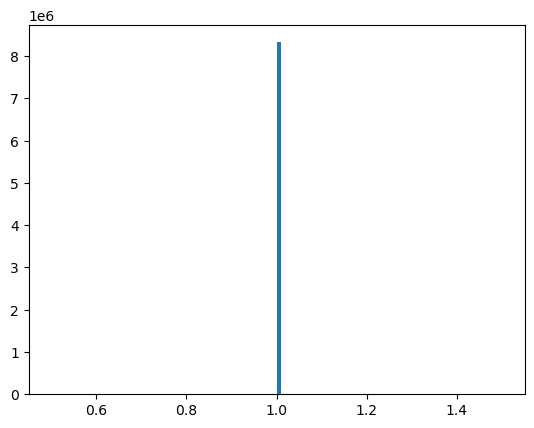

In [57]:
plt.hist(particles['vel_disp']==0,bins=100)

In [53]:
particles

rec.array([([-761.3906  ,    3.34375 ,    9.59375 ], [ -52., -160.,   56.], [ 66, 258, 258], 0., 0., False, 0, 0.),
           ([-761.8906  ,   11.9375  ,    8.5     ], [ -68., -140.,   20.], [ 66, 260, 258], 0., 0., False, 0, 0.),
           ([-752.75    ,    3.640625,    8.140625], [ -24., -156.,    0.], [ 68, 258, 258], 0., 0., False, 0, 0.),
           ...,
           ([ 240.40625 ,   -6.984375,   -6.46875 ], [  16.,   36.,   56.], [316, 254, 254], 0., 0., False, 0, 0.),
           ([ 247.75    ,   -6.625   ,   -6.203125], [  -8.,   48.,   64.], [318, 254, 254], 0., 0., False, 0, 0.),
           ([ 248.39062 ,   -5.9375  ,  -15.578125], [  16.,   72.,   16.], [318, 254, 252], 0., 0., False, 0, 0.)],
          dtype=[('pos', '<f4', (3,)), ('vel', '<f4', (3,)), ('pid', '<u2', (3,)), ('density', '<f4'), ('vel_disp', '<f4'), ('is_map', '?'), ('mult', '<u4'), ('rel_vel', '<f4')])